In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('ggplot')
sns.set_theme()
import warnings; warnings.filterwarnings('ignore')


In [4]:

df = pd.read_csv("marketing_campaign_dataset.csv")
df.head()

,Campaign_ID,Company,Campaign_Type,Target_Audience,Duration,Channel_Used,Conversion_Rate,Acquisition_Cost,ROI,Location,Language,Clicks,Impressions,Engagement_Score,Customer_Segment,Date
0,1,Innovate Industries,Email,Men 18-24,30 days,Google Ads,0.04,"$16,174.00",6.29,Chicago,Spanish,506,1922,6,Health & Wellness,2021-01-01
1,2,NexGen Systems,Email,Women 35-44,60 days,Google Ads,0.12,"$11,566.00",5.61,New York,German,116,7523,7,Fashionistas,2021-01-02
2,3,Alpha Innovations,Influencer,Men 25-34,30 days,YouTube,0.07,"$10,200.00",7.18,Los Angeles,French,584,7698,1,Outdoor Adventurers,2021-01-03
3,4,DataTech Solutions,Display,All Ages,60 days,YouTube,0.11,"$12,724.00",5.55,Miami,Mandarin,217,1820,7,Health & Wellness,2021-01-04
4,5,NexGen Systems,Email,Men 25-34,15 days,YouTube,0.05,"$16,452.00",6.50,Los Angeles,Mandarin,379,4201,3,Health & Wellness,2021-01-05


In [5]:
display(df.shape)
display(df.info())
display(df.describe())
display(df.isnull().sum())

(200000, 16)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Campaign_ID       200000 non-null  int64  
 1   Company           200000 non-null  object 
 2   Campaign_Type     200000 non-null  object 
 3   Target_Audience   200000 non-null  object 
 4   Duration          200000 non-null  object 
 5   Channel_Used      200000 non-null  object 
 6   Conversion_Rate   200000 non-null  float64
 7   Acquisition_Cost  200000 non-null  object 
 8   ROI               200000 non-null  float64
 9   Location          200000 non-null  object 
 10  Language          200000 non-null  object 
 11  Clicks            200000 non-null  int64  
 12  Impressions       200000 non-null  int64  
 13  Engagement_Score  200000 non-null  int64  
 14  Customer_Segment  200000 non-null  object 
 15  Date              200000 non-null  object 
dtypes: float64(2), int64

None

,Campaign_ID,Conversion_Rate,ROI,Clicks,Impressions,Engagement_Score
count,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,100000.500000,0.080070,5.002438,549.772030,5507.301520,5.494710
std,57735.171256,0.040602,1.734488,260.019056,2596.864286,2.872581
min,1.000000,0.010000,2.000000,100.000000,1000.000000,1.000000
25%,50000.750000,0.050000,3.500000,325.000000,3266.000000,3.000000
50%,100000.500000,0.080000,5.010000,550.000000,5517.500000,5.000000
75%,150000.250000,0.120000,6.510000,775.000000,7753.000000,8.000000
max,200000.000000,0.150000,8.000000,1000.000000,10000.000000,10.000000


,0
Campaign_ID,0
Company,0
Campaign_Type,0
Target_Audience,0
Duration,0
Channel_Used,0
Conversion_Rate,0
Acquisition_Cost,0
ROI,0
Location,0


In [7]:
# 1. Column names
df.columns = df.columns.str.strip().str.lower()

# 2. Cost: "$16,174.00" -> 16174.0
df["acquisition_cost"] = (df["acquisition_cost"].astype(str)
                          .str.replace(r"[\$,]", "", regex=True).astype(float))

# 3. Duration: "30 days" -> 30
df["duration"] = df["duration"].astype(str).str.extract(r"(\d+)").astype(float)

# 4. Date
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# 5. Duplicates & missing
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()
print(df.isnull().sum())
df = df.dropna(subset=["channel_used", "acquisition_cost", "clicks", "impressions"])

# 6. Text cleanup
df["channel_used"] = df["channel_used"].str.strip().str.title()

# 7. Invalid rows
df = df[(df["acquisition_cost"] > 0) & (df["clicks"] <= df["impressions"])]

print("Final shape:", df.shape)


Duplicates: 0
campaign_id         0
company             0
campaign_type       0
target_audience     0
duration            0
channel_used        0
conversion_rate     0
acquisition_cost    0
roi                 0
location            0
language            0
clicks              0
impressions         0
engagement_score    0
customer_segment    0
date                0
dtype: int64
Final shape: (200000, 16)


In [8]:
# Conversions = Clicks x Conversion Rate
df["conversions"] = df["clicks"] * df["conversion_rate"]

# ROI = (Revenue - Cost) / Cost  =>  Revenue = Cost x (1 + ROI)
df["revenue"] = df["acquisition_cost"] * (1 + df["roi"])

In [9]:
ch = df.groupby("channel_used").agg(
    spend=("acquisition_cost", "sum"),
    impressions=("impressions", "sum"),
    clicks=("clicks", "sum"),
    conversions=("conversions", "sum"),
    revenue=("revenue", "sum"),
    avg_engagement=("engagement_score", "mean"),
).reset_index()

ch["ctr_%"]   = ch["clicks"] / ch["impressions"] * 100
ch["cpa"]     = ch["spend"] / ch["conversions"]
ch["roi_%"]   = (ch["revenue"] - ch["spend"]) / ch["spend"] * 100
ch["spend_share_%"] = ch["spend"] / ch["spend"].sum() * 100

ch = ch.sort_values("roi_%", ascending=False)
print(ch.round(2))

  channel_used        spend  impressions    clicks  conversions       revenue  \
1     Facebook  410595258.0    180659428  18037947   1446290.30  2.474541e+09   
4      Website  416593500.0    183806353  18414628   1477710.16  2.504152e+09   
2   Google Ads  418912314.0    185006879  18340807   1468753.09  2.516724e+09   
5      Youtube  416778582.0    183448082  18350407   1463568.01  2.501105e+09   
0        Email  420874104.0    184801107  18493963   1485393.65  2.524644e+09   
3    Instagram  417124850.0    183738455  18316654   1462864.48  2.497101e+09   

   avg_engagement  ctr_%     cpa   roi_%  spend_share_%  
1            5.50   9.98  283.90  502.67          16.42  
4            5.51  10.02  281.92  501.10          16.66  
2            5.49   9.91  285.22  500.78          16.75  
5            5.48  10.00  284.77  500.10          16.67  
0            5.49  10.01  283.34  499.86          16.83  
3            5.49   9.97  285.14  498.65          16.68  


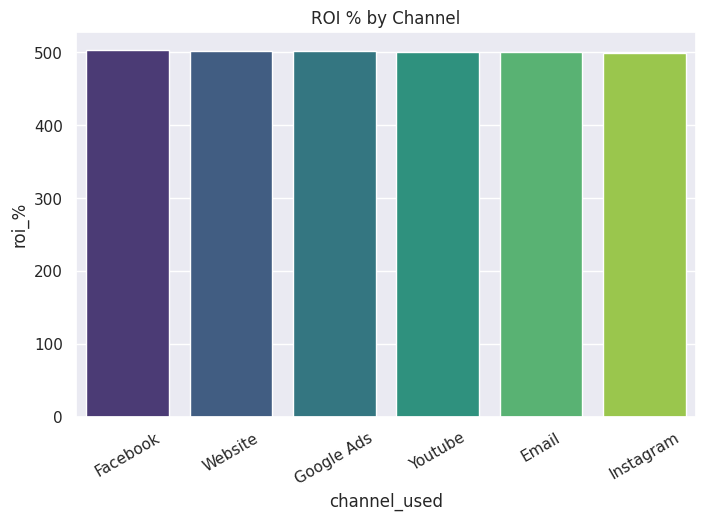

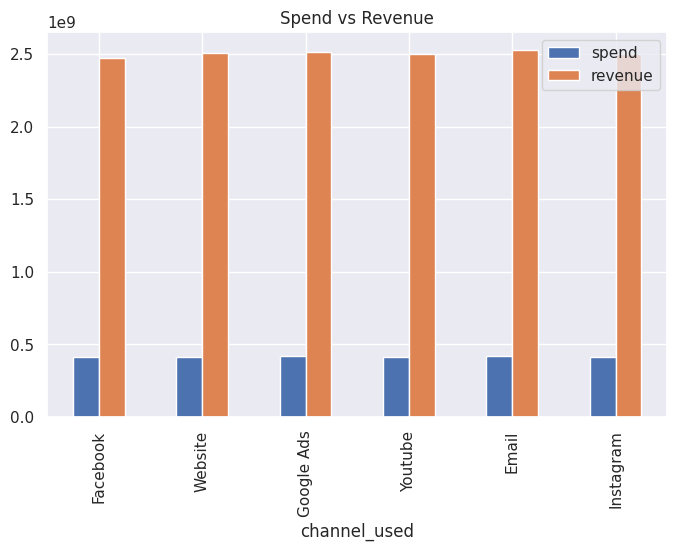

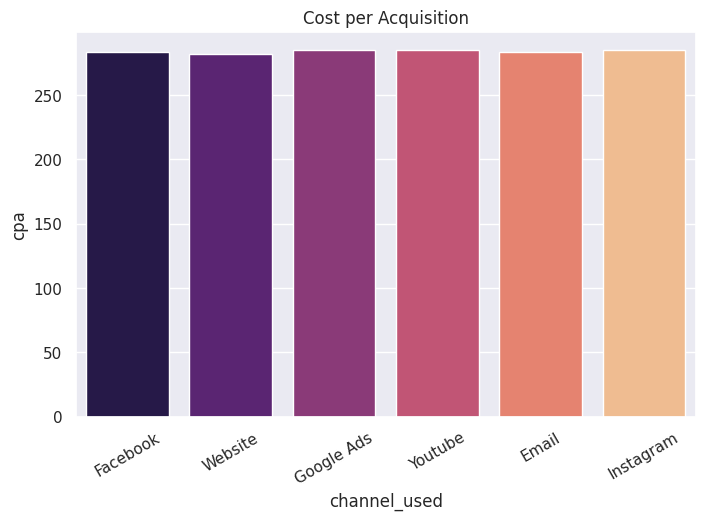

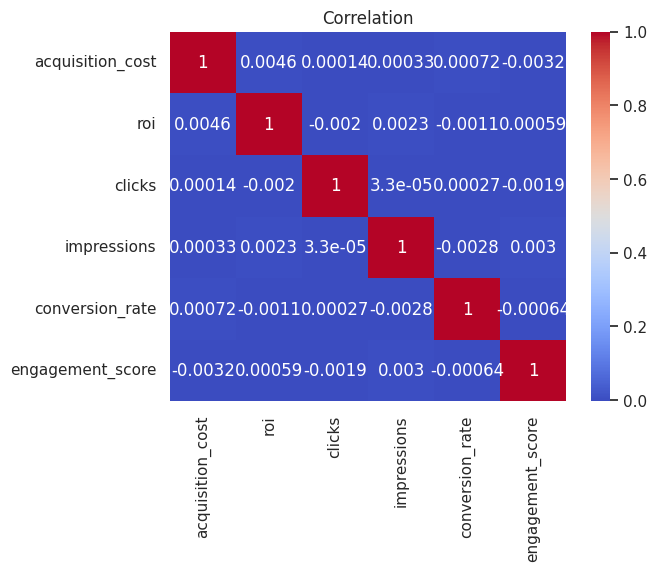

In [10]:
# a) Funnel
funnel = pd.DataFrame({
    "stage": ["Impressions", "Clicks", "Conversions"],
    "count": [df.impressions.sum(), df.clicks.sum(), df.conversions.sum()]
})
fig = px.funnel(funnel, x="count", y="stage", title="Marketing Funnel")
fig.show()

# b) ROI by channel
plt.figure(figsize=(8,5))
sns.barplot(data=ch, x="channel_used", y="roi_%", palette="viridis")
plt.title("ROI % by Channel"); plt.xticks(rotation=30)
plt.savefig("roi.png", dpi=200, bbox_inches="tight"); plt.show()

# c) Spend vs Revenue
ch.set_index("channel_used")[["spend", "revenue"]].plot(kind="bar", figsize=(8,5))
plt.title("Spend vs Revenue"); plt.savefig("spend_revenue.png", dpi=200, bbox_inches="tight"); plt.show()

# d) Cost per Conversion
plt.figure(figsize=(8,5))
sns.barplot(data=ch, x="channel_used", y="cpa", palette="magma")
plt.title("Cost per Acquisition"); plt.xticks(rotation=30)
plt.savefig("cpa.png", dpi=200, bbox_inches="tight"); plt.show()

# e) Correlation heatmap (EDA kosam)
sns.heatmap(df[["acquisition_cost","roi","clicks","impressions","conversion_rate","engagement_score"]].corr(),
            annot=True, cmap="coolwarm")
plt.title("Correlation"); plt.show()

In [11]:
print("Best ROI :", ch.iloc[0]["channel_used"], round(ch.iloc[0]["roi_%"], 1))
print("Worst ROI:", ch.iloc[-1]["channel_used"], round(ch.iloc[-1]["roi_%"], 1))
print(ch[["channel_used", "spend_share_%", "roi_%", "cpa"]].round(1))

Best ROI : Facebook 502.7
Worst ROI: Instagram 498.6
  channel_used  spend_share_%  roi_%    cpa
1     Facebook           16.4  502.7  283.9
4      Website           16.7  501.1  281.9
2   Google Ads           16.8  500.8  285.2
5      Youtube           16.7  500.1  284.8
0        Email           16.8  499.9  283.3
3    Instagram           16.7  498.6  285.1
